# Quantum Autoencoder vs PCA for Downsampled MNIST Digits
**A simulator-based comparison** · Qiskit, Qiskit Aer, NumPy, SciPy

This notebook walks through the whole project step by step: data → amplitude encoding → circuit → cost function → training → comparison with PCA → extensions.
Every quantum operation is verified against Qiskit (see also `pytest -q`).

In [1]:
import sys, os, warnings
sys.path.insert(0, os.path.abspath(".."))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from qiskit.quantum_info import Operator, Statevector
from qae.data import make_dataset
from qae.ansatz import build_unitary, n_params
from qae.circuits import ansatz_circuit, swap_test_p0, qae_circuit
from qae.metrics import reconstruct, fidelity_reset, fidelity_ps, readout_reset, readout_ps, readout_mse
from qae.train import train_qae, second_moment, ideal_cost_bound, param_shift_grad, trash_cost
from qae.pca_baseline import PCABaseline
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
RES = os.path.abspath("../results")

## 1 · Data: MNIST → 4×4 → amplitudes
28×28 images are reduced to 4×4 by exact 7×7 block averaging, flattened to 16 numbers and **L2-normalised**:
$$|\psi\rangle=\sum_{i=0}^{15}\frac{x_i}{\|x\|_2}\,|i\rangle\qquad(4\text{ qubits}).$$
Normalisation is mandatory for a quantum state, and it discards the overall brightness of the image.

train: (700, 16)  test: (300, 16)
norms (should be 1): [1. 1. 1.]


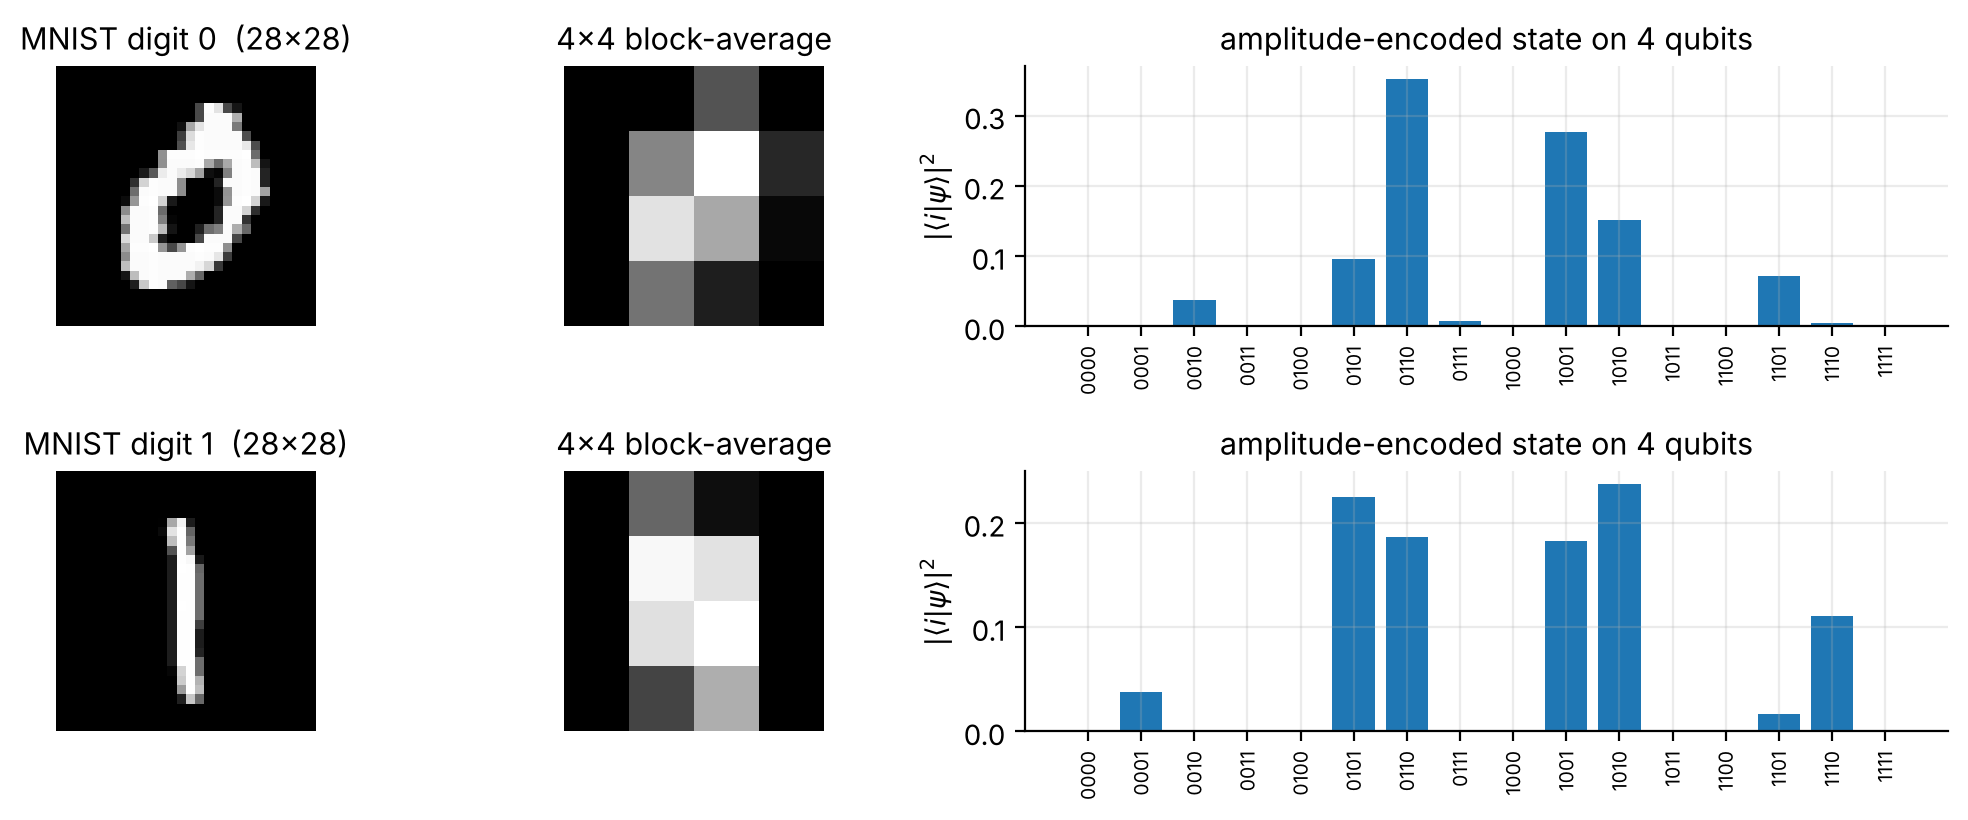

In [2]:
ds = make_dataset((0, 1), seed=0)
print("train:", ds["psi_train"].shape, " test:", ds["psi_test"].shape)
print("norms (should be 1):", np.linalg.norm(ds["psi_train"][:3], axis=1))
display(Image(os.path.join(RES, "figures", "fig_dataset.png")))

## 2 · The quantum circuit
Ansatz (one layer = RY on every qubit + a CX chain): $U(\theta)=R_L\,[E R_{L-1}]\cdots[E R_0]$. All gates are real, so $U$ is an orthogonal $16\times16$ matrix – enough because MNIST amplitudes are real.
Our fast NumPy simulator is checked against Qiskit's `Operator`:

max |U_numpy - U_qiskit| = 4.440892098500626e-16
orthogonal: True


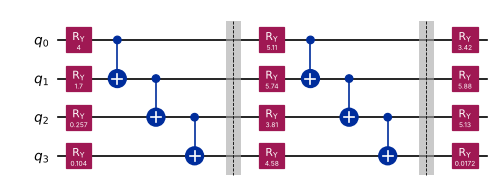

In [3]:
L = 3
th = np.random.default_rng(0).uniform(0, 2*np.pi, n_params(L))
U_numpy  = build_unitary(th, L)
U_qiskit = Operator(ansatz_circuit(th, L)).data
print("max |U_numpy - U_qiskit| =", np.abs(U_numpy - U_qiskit).max())
print("orthogonal:", np.allclose(U_numpy @ U_numpy.T, np.eye(16)))
ansatz_circuit(th[:n_params(2)], 2).draw("mpl", scale=0.6)

## 3 · Autoencoder = compress by *resetting* the trash qubits
With $k$ latent qubits the other $4-k$ are **trash**. After $U$ the trash is reset to $|0\ldots0\rangle$ and $U^\dagger$ is applied (decoder).
Training makes the trash already be $|0\ldots0\rangle$, so that resetting loses little.

**Cost** (Romero et al., 2017): $C(\theta)=1-\mathbb E\,[P(\text{trash}=0\ldots0)]$. It can be measured on hardware with a **swap test** against reference $|0\rangle$ qubits:
$P(\text{ancilla}=0)=\tfrac12\,(1+p_0)$. We verify that the swap-test circuit reproduces our formula:

In [4]:
k = 2
rec = reconstruct(U_numpy, ds["psi_test"][:5], k)
for i in range(3):
    print(f"sample {i}:  p0 (simulator) = {rec['p0'][i]:.6f}   p0 (Qiskit swap-test circuit) = {swap_test_p0(ds['psi_test'][i], th, L, k):.6f}")

sample 0:  p0 (simulator) = 0.116942   p0 (Qiskit swap-test circuit) = 0.116942
sample 1:  p0 (simulator) = 0.202142   p0 (Qiskit swap-test circuit) = 0.202142
sample 2:  p0 (simulator) = 0.136757   p0 (Qiskit swap-test circuit) = 0.136757


## 4 · Training
Gradient by the **parameter-shift rule** (exact for RY gates); optimiser L-BFGS-B with several random restarts. First, verify the gradient against finite differences:

In [5]:
C = second_moment(ds["psi_train"])
g_ps = param_shift_grad(th, C, L, k)
eps = 1e-6
g_fd = np.array([(trash_cost(th+eps*e, C, L, k) - trash_cost(th-eps*e, C, L, k))/(2*eps) for e in np.eye(len(th))])
print("max |parameter-shift - finite-difference| =", np.abs(g_ps - g_fd).max())

max |parameter-shift - finite-difference| = 1.4527729019775393e-10


final cost 0.0522   Ky-Fan lower bound 0.0427   (training took 2.4s)


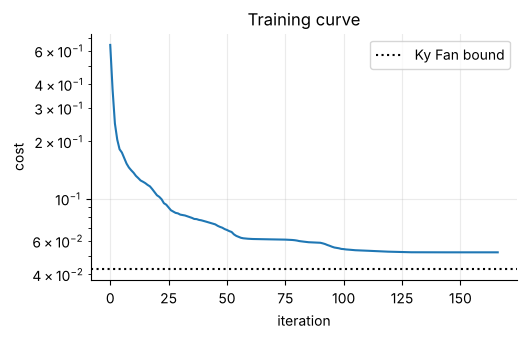

In [6]:
k, L = 2, 6
fit = train_qae(ds["psi_train"], L, k, n_restarts=5, seed=0, maxiter=400)
print(f"final cost {fit['final_cost']:.4f}   Ky-Fan lower bound {fit['bound']:.4f}   (training took {fit['train_time_s']:.1f}s)")
plt.figure(figsize=(5.5, 3.2)); plt.plot(fit["history"]); plt.axhline(fit["bound"], c="k", ls=":", label="Ky Fan bound")
plt.yscale("log"); plt.xlabel("iteration"); plt.ylabel("cost"); plt.legend(); plt.title("Training curve"); plt.show()

## 5 · Comparison with PCA at matched latent size
$k$ latent qubits ↔ $K=2^k$ PCA components. Two decoders for the QAE:
* **reset** – trace-preserving quantum channel (what a real device does),
* **post-selected** – keep only runs where the trash reads $|0\ldots0\rangle$; fidelity $=P(\text{trash}=0)$.

PCA reconstructions are re-normalised to unit vectors so that they are valid states.

In [7]:
U = build_unitary(fit["theta"], L); psi = ds["psi_test"]
rec = reconstruct(U, psi, k)
pu = PCABaseline(2**k, centered=False).fit(ds["psi_train"]); pc = PCABaseline(2**k, centered=True).fit(ds["psi_train"])
tbl = pd.DataFrame({
    "fidelity": [fidelity_reset(rec, psi).mean(), fidelity_ps(rec, psi).mean(), pu.fidelity(psi).mean(), pc.fidelity(psi).mean()],
    "readout MSE": [readout_mse(psi, readout_reset(rec)).mean(), readout_mse(psi, readout_ps(rec)).mean(),
                    readout_mse(psi, pu.readout(psi)).mean(), readout_mse(psi, pc.readout(psi)).mean()]},
    index=["QAE reset", "QAE post-selected", "PCA uncentred (matched)", "PCA centred (standard)"]).round(4)
tbl

,fidelity,readout MSE
QAE reset,0.9103,0.0037
QAE post-selected,0.9468,0.0034
PCA uncentred (matched),0.9554,0.0029
PCA centred (standard),0.9694,0.0020


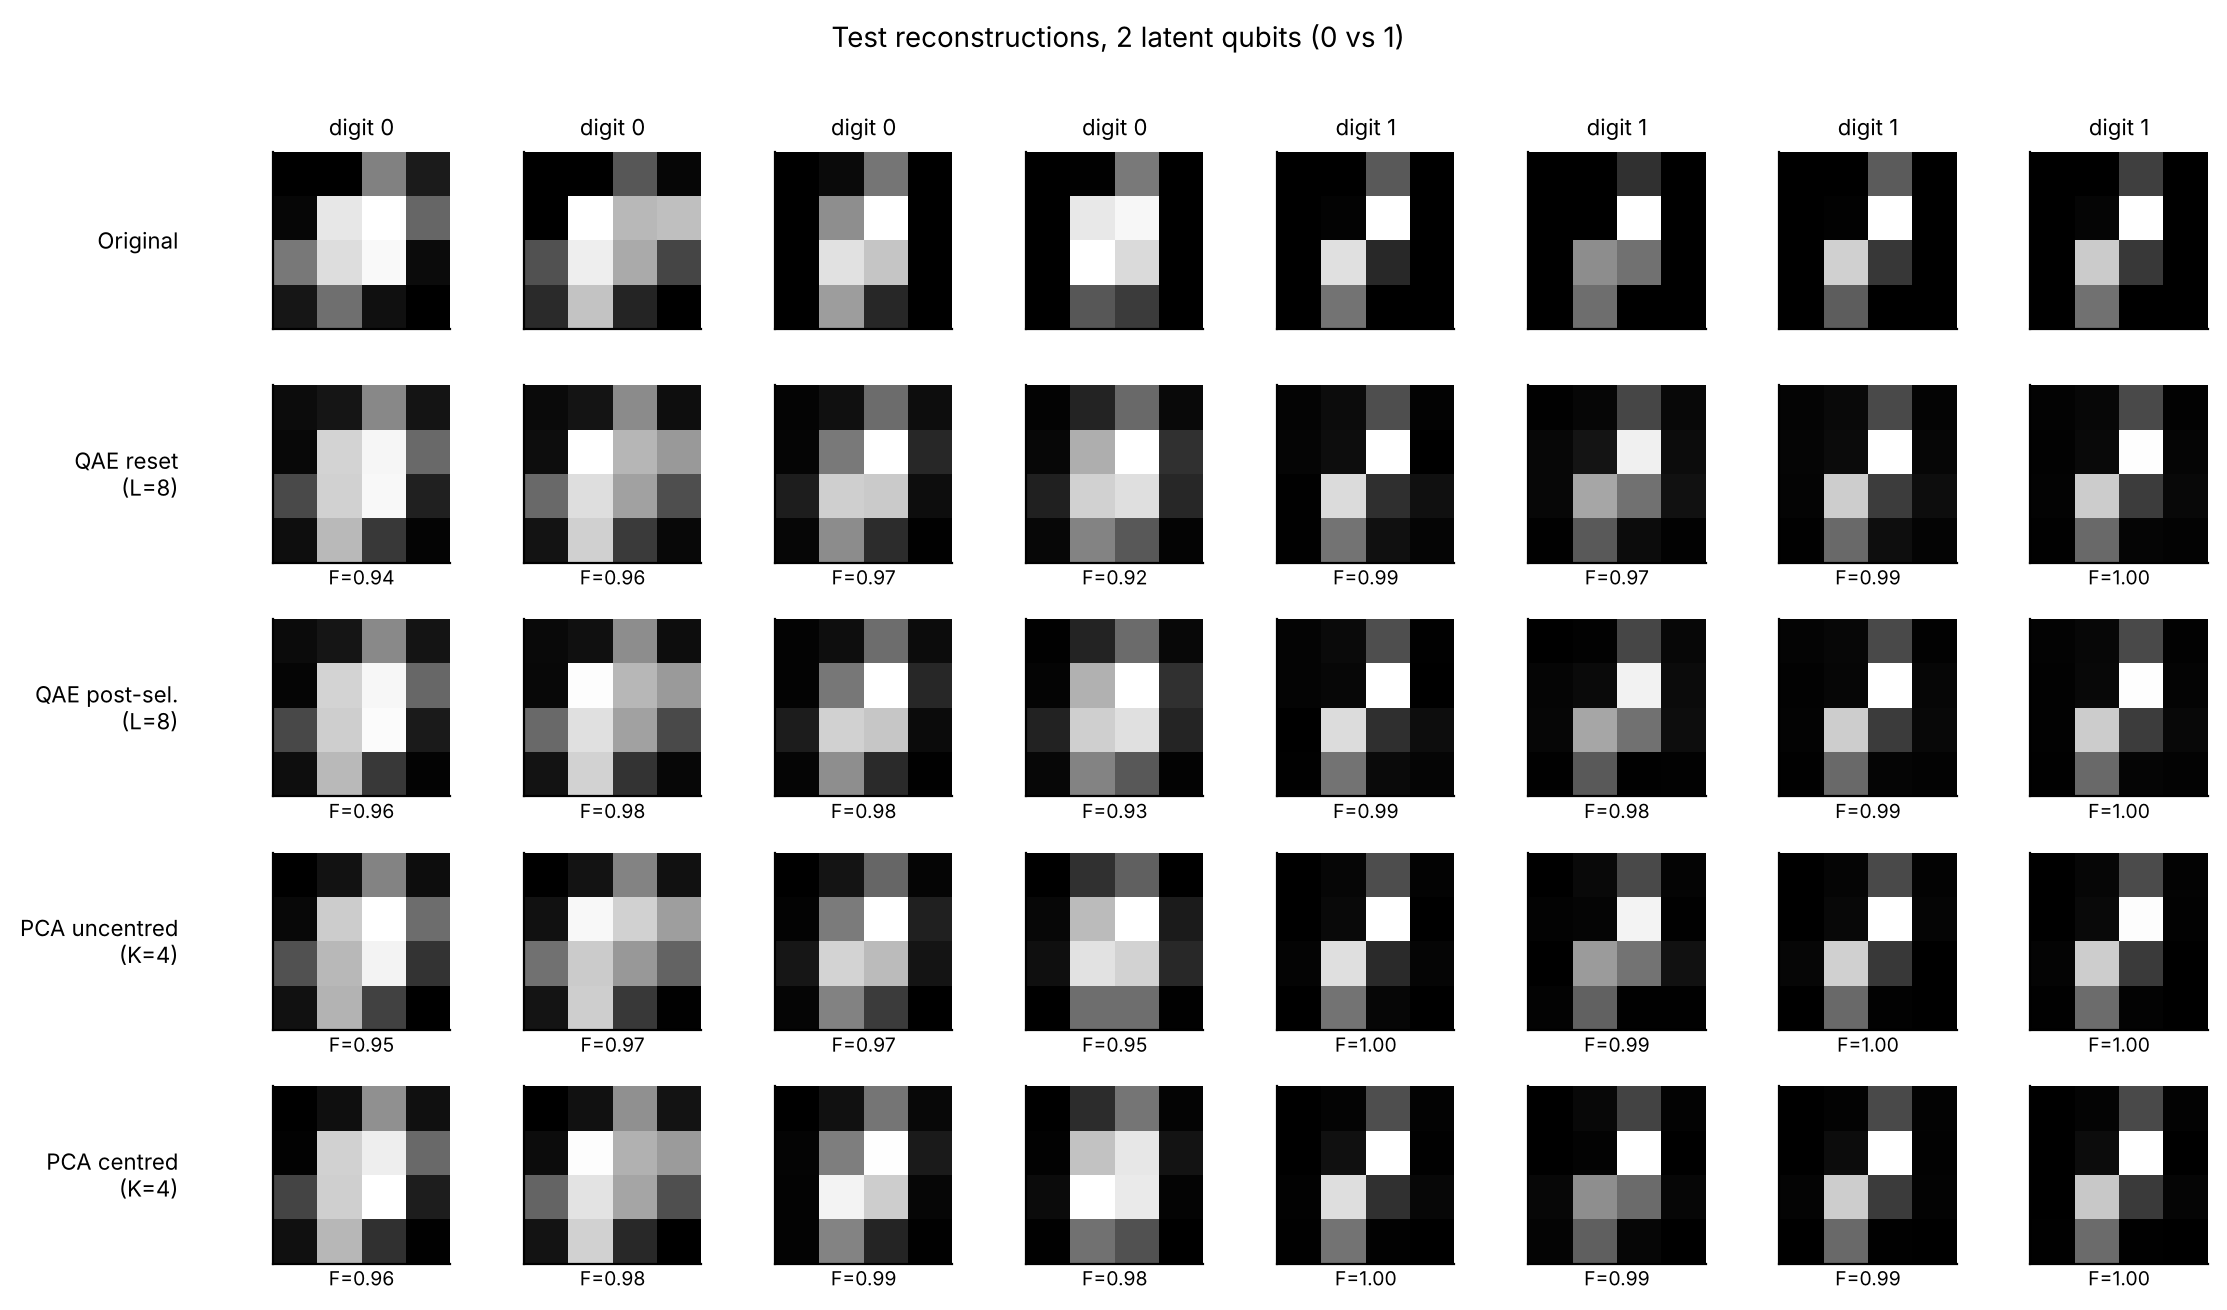

In [8]:
display(Image(os.path.join(RES, "figures", "fig_reconstructions_0vs1_k2.png")))

## 6 · Why PCA is a hard ceiling: the Ky Fan theorem
$P(\text{trash}=0)=\mathrm{Tr}[\Pi U\Sigma U^\top]$ with $\Sigma=\mathbb E[\psi\psi^\top]$. Its maximum over **all** orthogonal $U$ is the sum of the $K$ largest eigenvalues of $\Sigma$ – exactly the variance captured by uncentred PCA. So a post-selected QAE can *match* PCA only in the limit of an expressive-enough circuit.

eigenvalues of Sigma: [7.998e-01 1.004e-01 4.090e-02 1.620e-02 1.500e-02 1.060e-02 6.100e-03
 3.900e-03 2.700e-03 1.800e-03 9.000e-04 8.000e-04 5.000e-04 3.000e-04
 1.000e-04 0.000e+00]
k=1: PCA (K=2) captures 0.9001  ->  best possible QAE cost = 0.0999
k=2: PCA (K=4) captures 0.9573  ->  best possible QAE cost = 0.0427
k=3: PCA (K=8) captures 0.9929  ->  best possible QAE cost = 0.0071


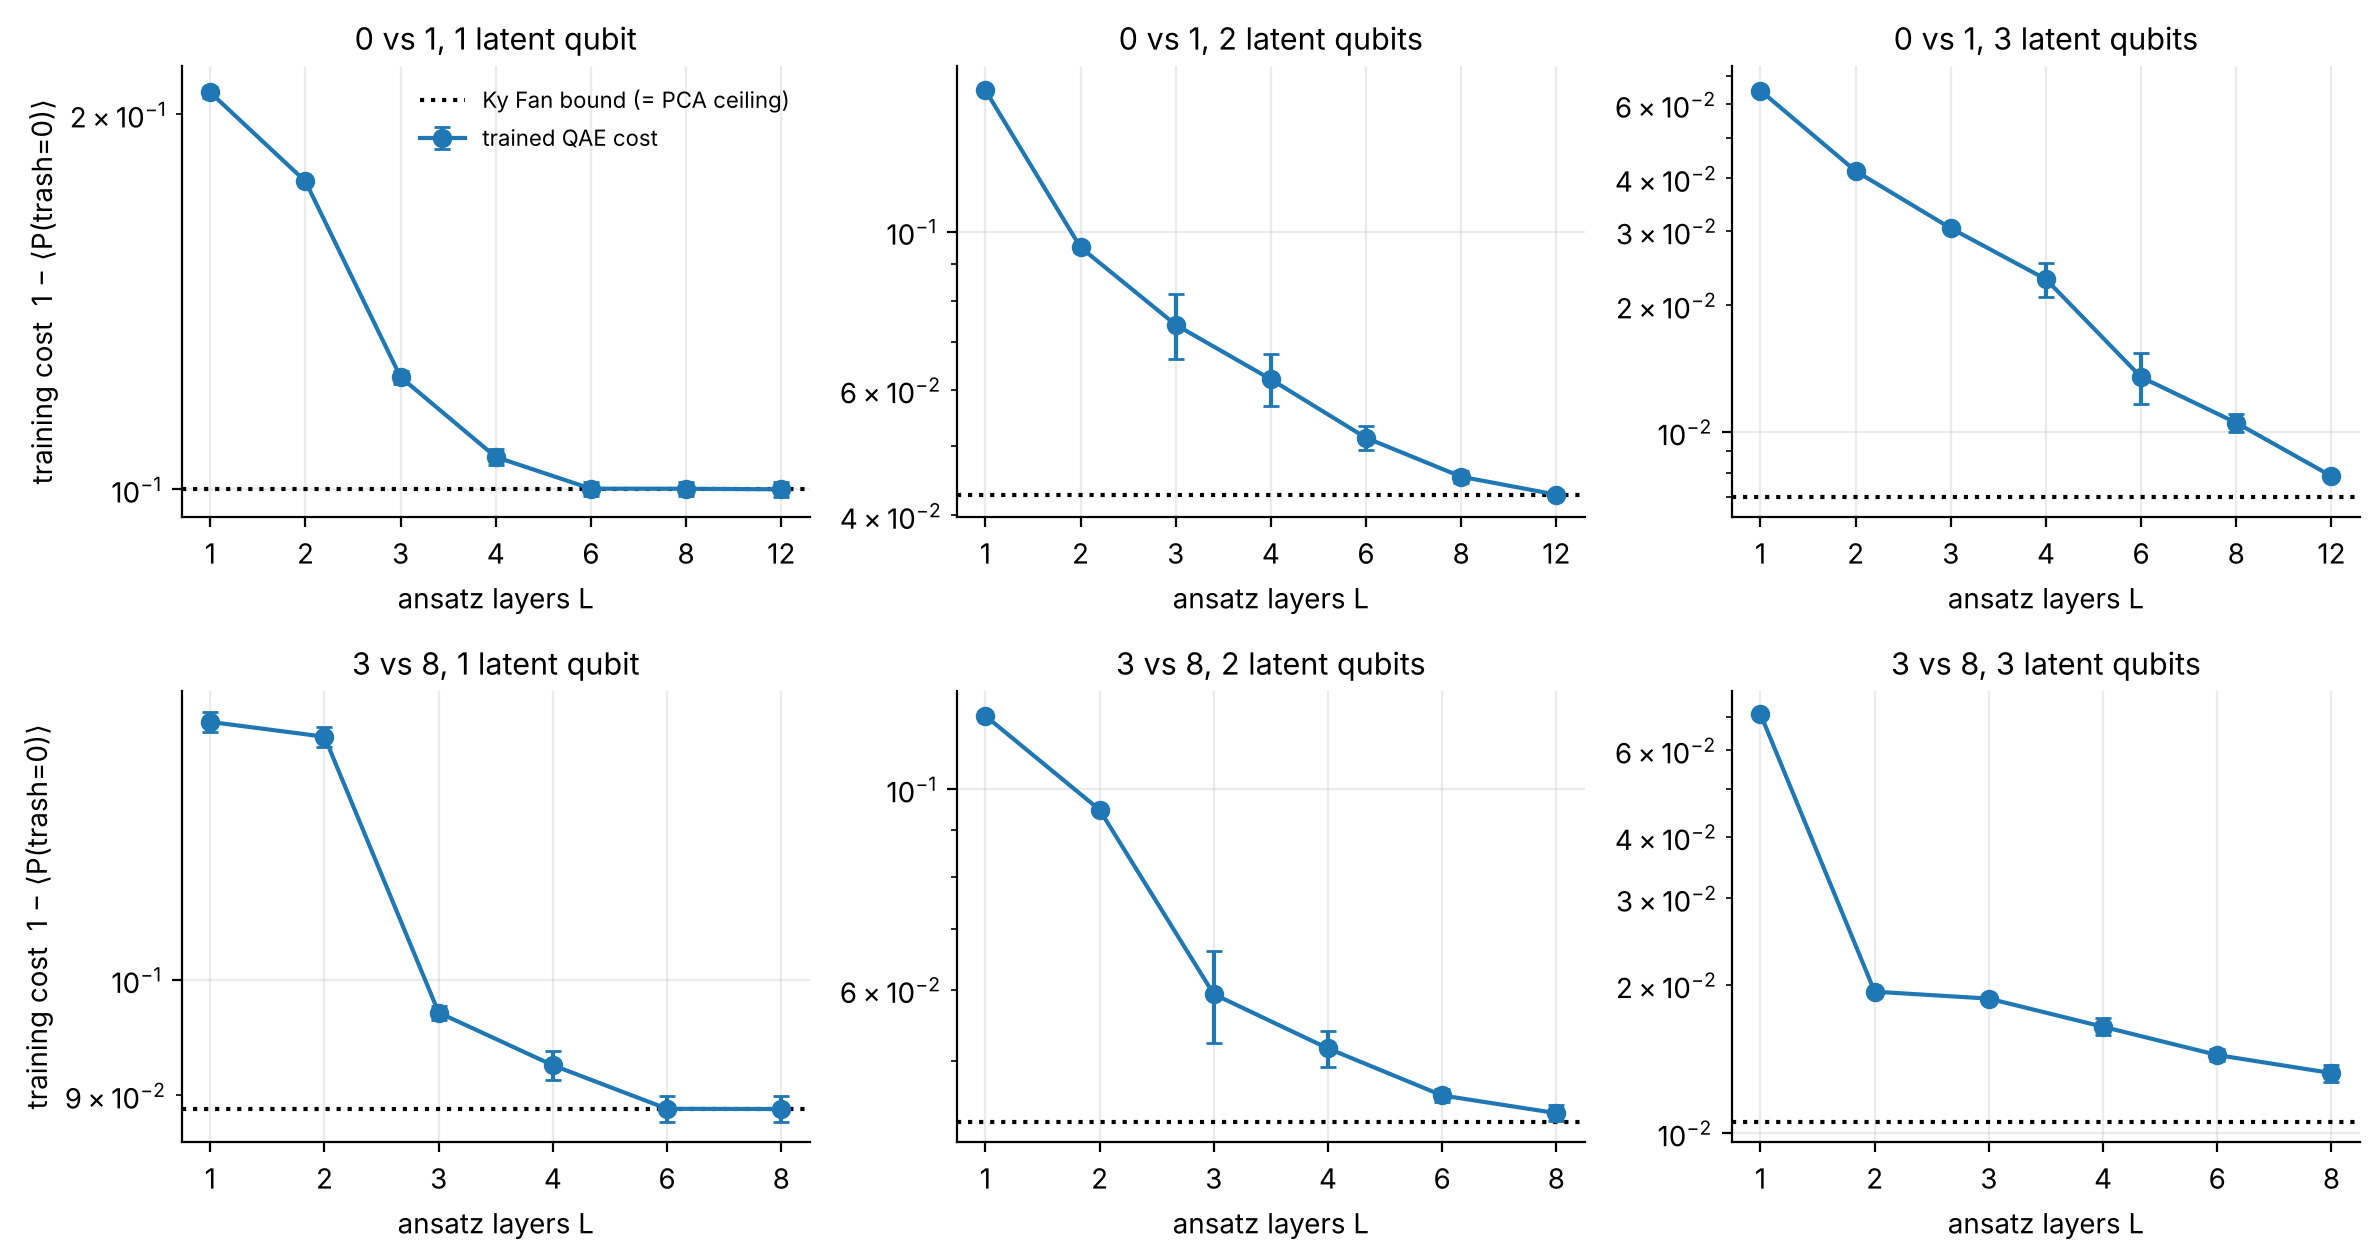

In [9]:
ev = np.sort(np.linalg.eigvalsh(second_moment(ds["psi_train"])))[::-1]
print("eigenvalues of Sigma:", ev.round(4))
for kk in (1, 2, 3):
    K = 2**kk
    print(f"k={kk}: PCA (K={K}) captures {ev[:K].sum():.4f}  ->  best possible QAE cost = {1-ev[:K].sum():.4f}")
display(Image(os.path.join(RES, "figures", "fig_cost_vs_bound.png")))

## 7 · Results over many splits and depths (precomputed by `run_all.py`)

In [10]:
q = pd.read_csv(os.path.join(RES, "qae_sweep.csv")); p = pd.read_csv(os.path.join(RES, "pca_baseline.csv"))
sel = q[(q.pair == "0 vs 1") & (q.k == 2)].groupby("layers")[["F_reset", "F_ps", "train_cost", "bound"]].mean().round(4)
sel["PCA unc."] = p[(p.pair == "0 vs 1") & (p.k == 2) & (~p.centered)].F.mean().round(4)
sel["PCA cent."] = p[(p.pair == "0 vs 1") & (p.k == 2) & (p.centered)].F.mean().round(4)
sel

,F_reset,F_ps,train_cost,bound,PCA unc.,PCA cent.
layers,,,,,,
1,0.7386,0.8413,0.1578,0.0427,0.9554,0.9699
2,0.8425,0.9035,0.0950,0.0427,0.9554,0.9699
3,0.8701,0.9233,0.0740,0.0427,0.9554,0.9699
4,0.8925,0.9354,0.0621,0.0427,0.9554,0.9699
6,0.9109,0.9468,0.0514,0.0427,0.9554,0.9699
8,0.9210,0.9526,0.0453,0.0427,0.9554,0.9699
12,0.9263,0.9555,0.0428,0.0428,0.9554,0.9699


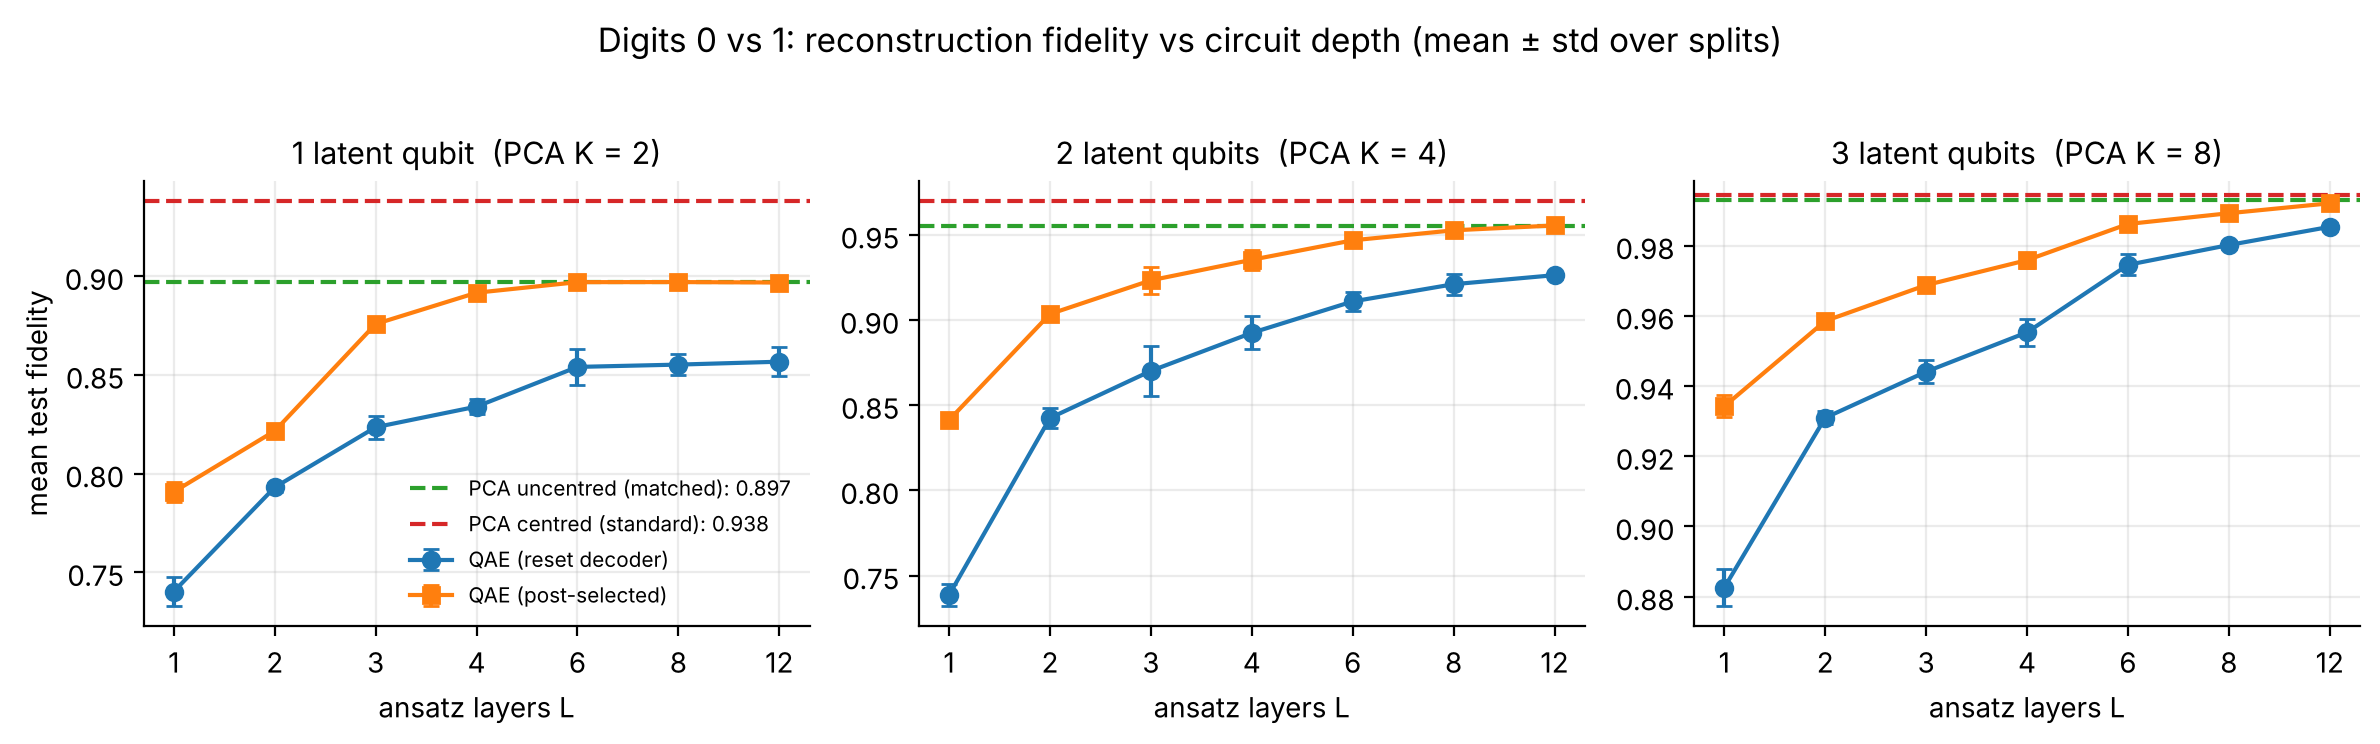

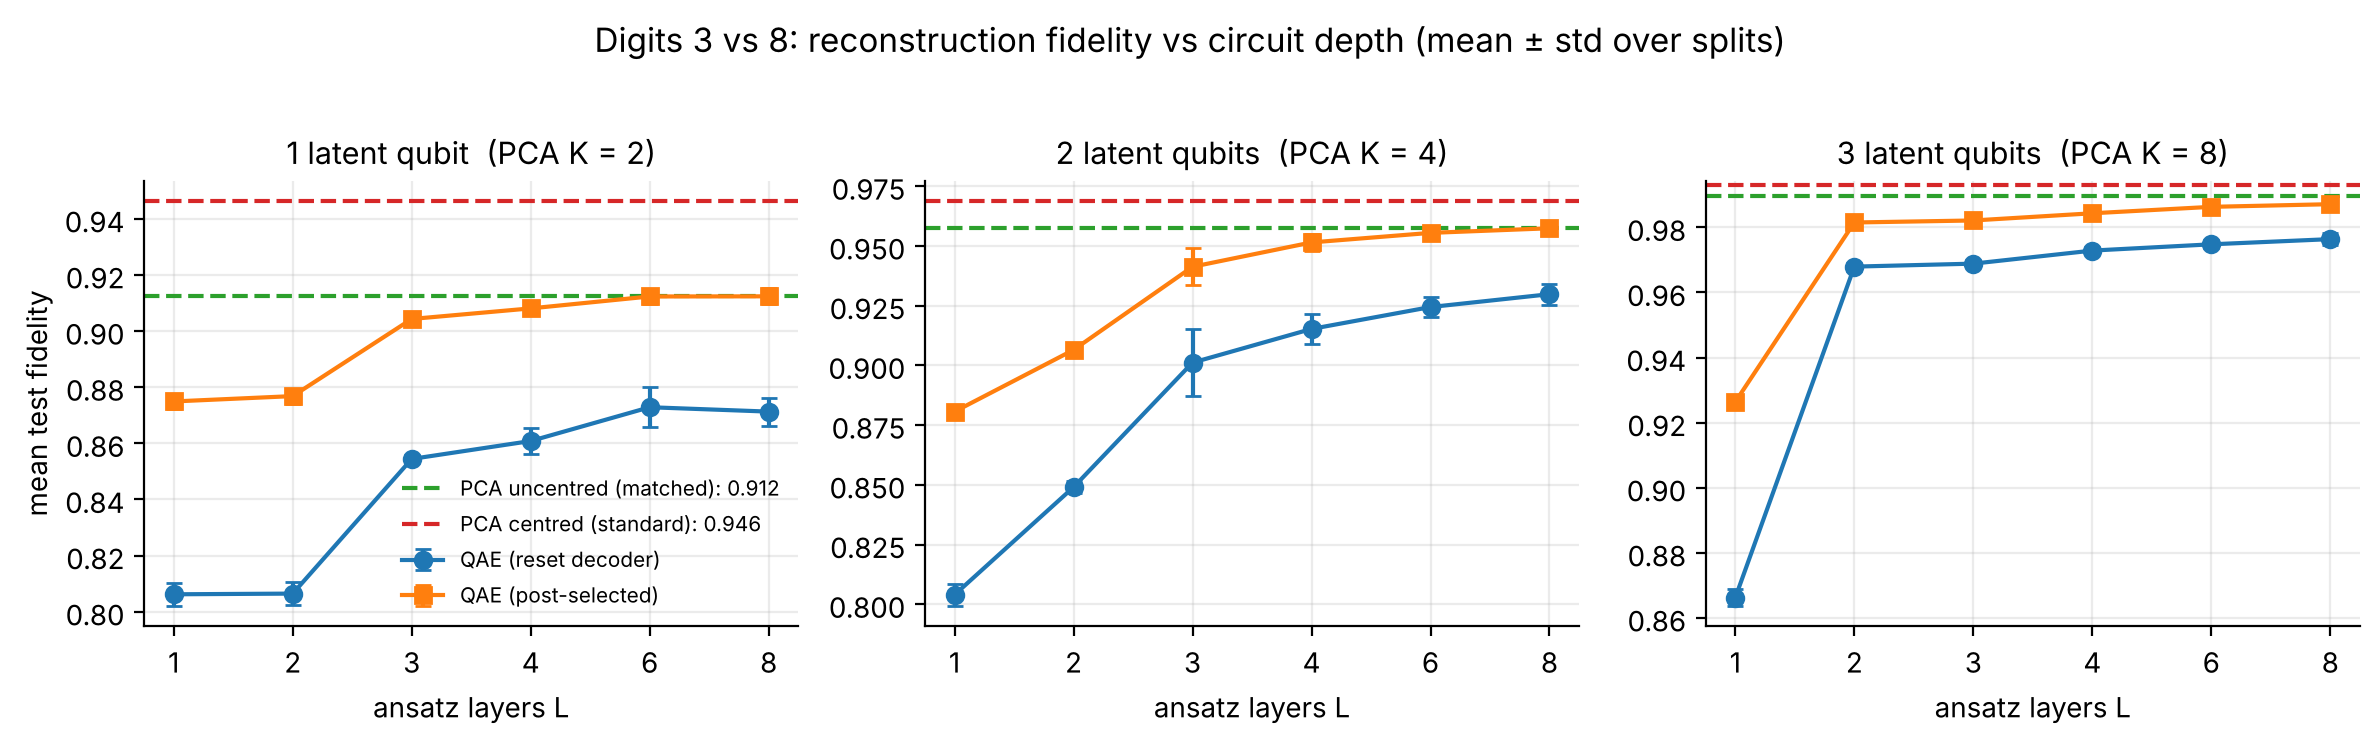

In [11]:
display(Image(os.path.join(RES, "figures", "fig_fidelity_vs_layers_0vs1.png")))
display(Image(os.path.join(RES, "figures", "fig_fidelity_vs_layers_3vs8.png")))

## 8 · Extensions
**Latent qubit on the Bloch sphere**, **shot-based measurement** of the complete circuit, **denoising**, and **gate-noise** robustness (Aer):

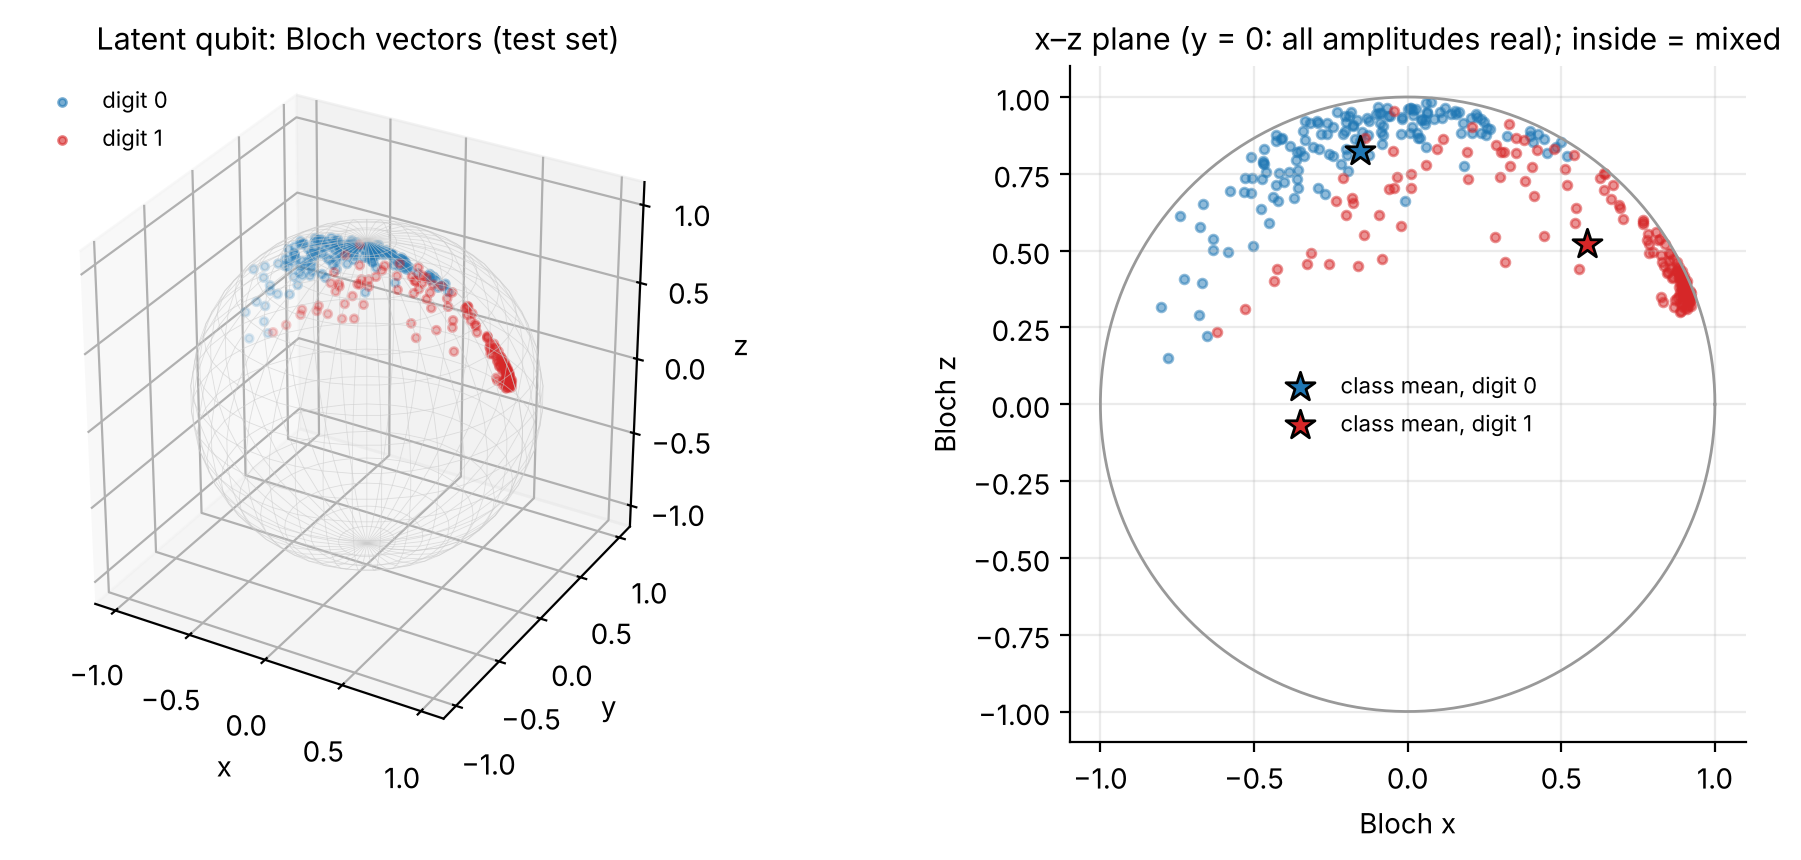

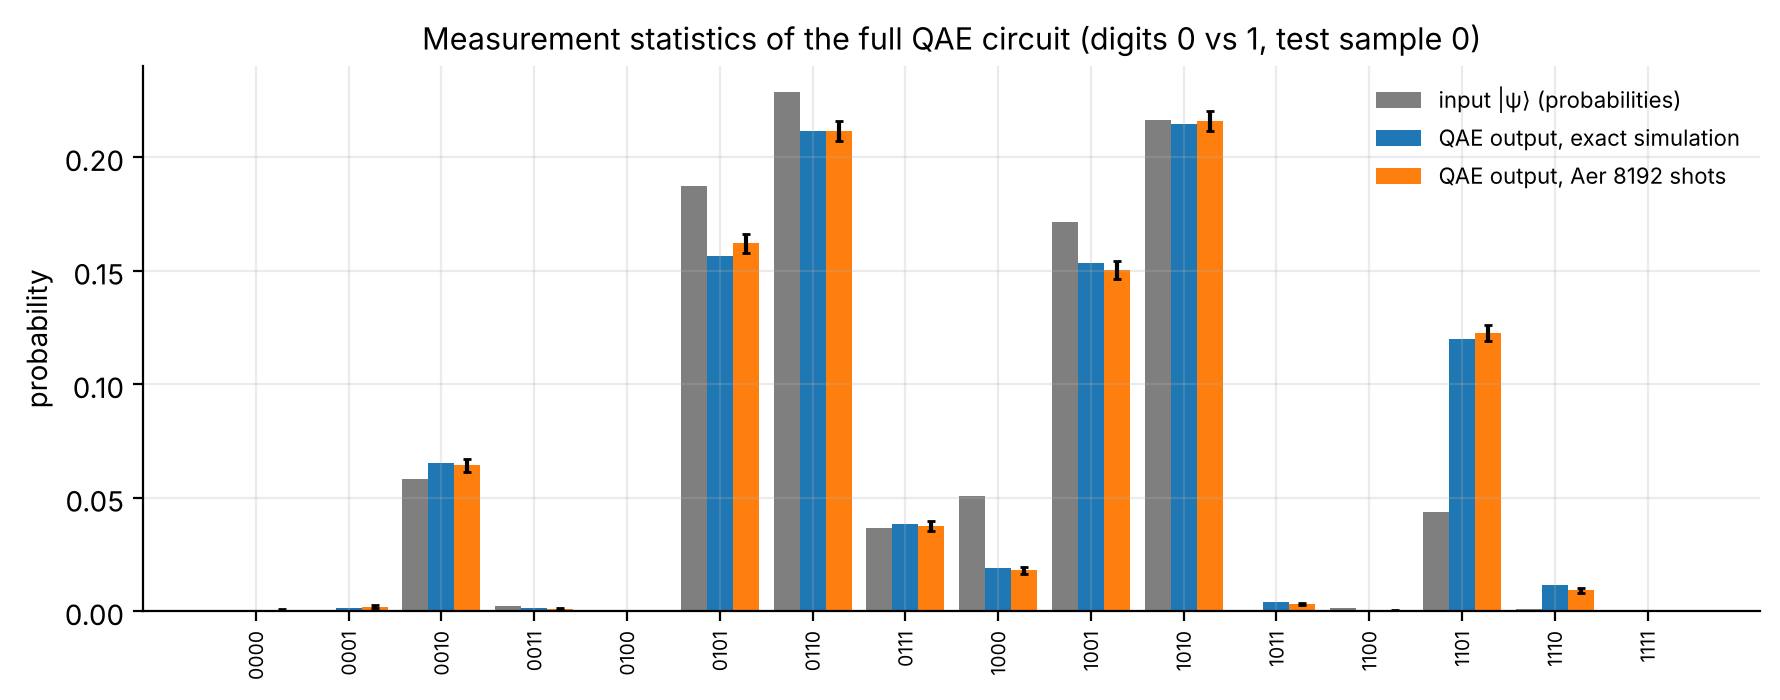

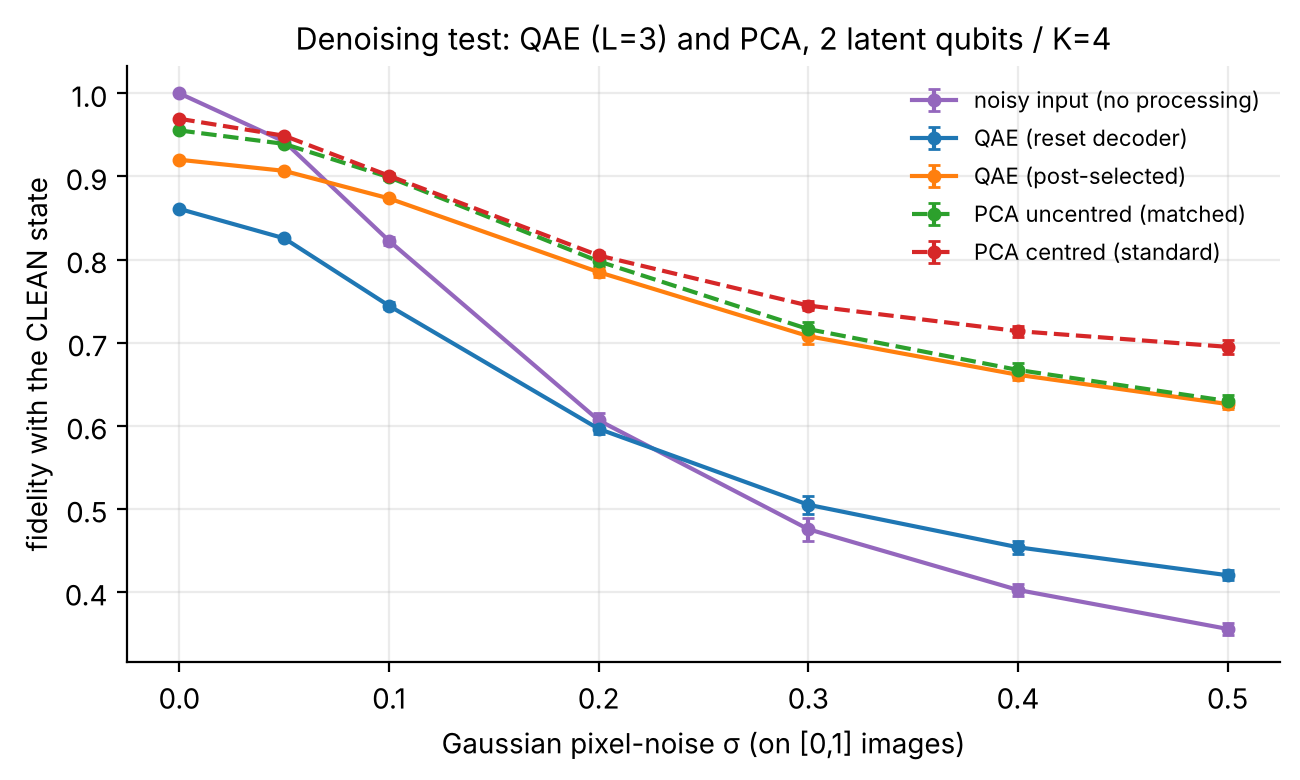

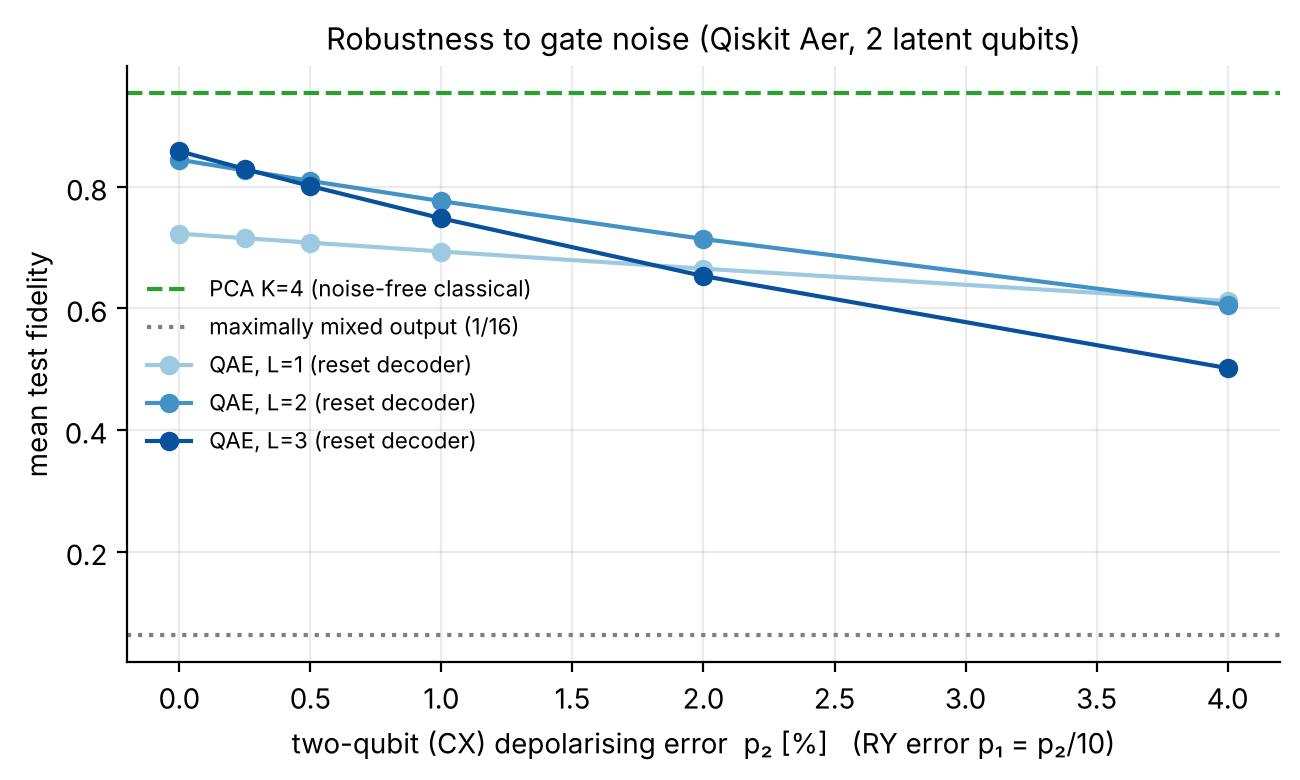

In [12]:
for f in ("fig_bloch_latent.png", "fig_measurement_shots.png", "fig_denoising.png", "fig_gate_noise.png"):
    display(Image(os.path.join(RES, "figures", f)))

## 9 · Take-aways
1. A small QAE trained with the Romero cost compresses 4×4 digit states and **approaches, but never exceeds, the PCA ceiling** (Ky Fan); deeper circuits close the gap.
2. At equal depth the reset decoder is worse than post-selection because it must stay trace-preserving; post-selection costs success probability instead.
3. Standard (centred) PCA slightly beats everything because it additionally stores a mean image.
4. Deeper circuits help without noise but are hit harder by gate noise; amplitude-encoding state preparation is more expensive than the autoencoder itself.
5. **No quantum advantage is claimed or observed** – everything here is classically simulated and PCA is faster and at least as accurate.